# Risco de atraso inicial na concessão de crédito

Este estudo estima a probabilidade de atraso nas primeiras parcela de um contrato. O objetivo é verificar se os dados disponíveis no momento da solicitação permitem identificar propostas que mereçam revisão adicional.


O fluxo cobre integridade das bases, contrução do desfecho, validação temporal, simulação da política de crédito e geração do arquivo submissao_case.csv

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
diretorio_config = os.environ.get("CASE_DATA_DIR")
diretorio_atual = Path.cwd()

if diretorio_config:
    DATA_DIR = Path(diretorio_config).expanduser().resolve()
elif diretorio_atual.name == "notebook":
    DATA_DIR = diretorio_atual.parent / "data"
else:
    DATA_DIR = diretorio_atual / "data"

arquivos_esperados = (
    "base_cadastral.parquet",
    "base_submissao.parquet",
    "historico_emprestimos.parquet",
    "historico_parcelas.parquet",
    "dicionario_dados.csv"
)

faltantes = [nome for nome in arquivos_esperados if not (DATA_DIR / nome).is_file()]
if faltantes:
    raise FileNotFoundError(f"Arquivos faltantes no diretório {DATA_DIR}: {faltantes}")
print(
    "Python", sys.version.split()[0],
    "| pandas", pd.__version__, 
    "| numpy", np.__version__, 
    "| sklearn", sklearn.__version__, 
    "| pyarrow", pyarrow.__version__)

cadastro = pd.read_parquet(DATA_DIR / "base_cadastral.parquet")
solicitacoes = pd.read_parquet(DATA_DIR / "base_submissao.parquet")
contratos = pd.read_parquet(DATA_DIR / "historico_emprestimos.parquet")
parcelas = pd.read_parquet(DATA_DIR / "historico_parcelas.parquet")
dicionario = pd.read_csv(DATA_DIR / "dicionario_dados.csv", sep=";")

Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | sklearn 1.9.0 | pyarrow 23.0.1


## 1. O que as bases permitem observar? 

A unidade da previsão é a solicitação. O histórico contém decisões por contrato e pode incluir recusas. O pagamento pertence a um contrato e pode aparecer em várias linhas para a mesma parcela. As estatísticas abaixo mostram cobertura e verificam se a união dessas tabelas preserva a granularidade.

In [2]:
for nome, base, chave in [
    ("Cadastro", cadastro, "id_cliente"),
    ("Solicitações", solicitacoes, "id_cliente"),
    ("Contratos", contratos, "id_contrato"),
]:
    assert base[chave].notna().all() and base[chave].is_unique, nome
    print(f"{nome}: {len(base)} registros, {len(base.columns)} colunas, chave primária: {chave}")
print(f"Parcelas: {len(parcelas)} registros, {len(parcelas.columns)} colunas, chave primária: (id_contrato, id_parcela)")

cliente_contrato = contratos.set_index("id_contrato")[["id_cliente"]]
assert parcelas["id_cliente"].eq(parcelas["id_contrato"].map(cliente_contrato["id_cliente"])).all()
display(pd.Series({
    "solicitacoes sem cadastro": (~solicitacoes["id_cliente"].isin(cadastro["id_cliente"])).sum(),
    "solicitacoes sem decisao historica": (~solicitacoes.id_cliente.isin(contratos.id_cliente)).sum(),
    "linhas de parcela sem data de pagamento": parcelas.data_real_pagamento.isna().sum(),
    "linhas excedentes por contrato/parcela": parcelas.duplicated(["id_contrato", "numero_parcela"]).sum(),
}))

display(contratos["status_contrato"].value_counts(dropna=False))
display(dicionario[dicionario["coluna"].isin(["valor_credito", "valor_solicitado", "versao_parcela"])])

Cadastro: 40000 registros, 16 colunas, chave primária: id_cliente
Solicitações: 40000 registros, 8 colunas, chave primária: id_cliente
Contratos: 186890 registros, 37 colunas, chave primária: id_contrato
Parcelas: 1390978 registros, 8 colunas, chave primária: (id_contrato, id_parcela)


solicitacoes sem cadastro                      0
solicitacoes sem decisao historica          2048
linhas de parcela sem data de pagamento      339
linhas excedentes por contrato/parcela     80046
dtype: int64

status_contrato
Approved        116182
Canceled         35767
Refused          32108
Unused offer      2833
Name: count, dtype: int64

,base,coluna,descricao
21,base_submissao,valor_credito,Valor total do crédito solicitado
34,historico_emprestimos,valor_solicitado,Valor inicialmente solicitado pelo cliente
35,historico_emprestimos,valor_credito,Valor efetivamente liberado
63,historico_parcelas,versao_parcela,Versão da parcela dentro do contrato (caso haj...


## 2. Qual atraso conseguimos medir?

Compare atrasos superiores a 7, 15 e 30 dias nas três primeiras parcelas. São limiares para o mesmo conceito de atraso inicial. Usar as parcelas 1 a 3 é uma definição operacional. Elas podem vencer depois do terceiro mês de contrato.

A definição principal usa o vencimento da maior versão da parcela. A menor versão serve como teste de sensibilidade. Em uma mesma versã0, a data de vencimento deve ser consistente. Usamos a última data de pagamento registrada nessa versão como aproximação da liquidação, inclusive quando há registros fracionados. A versão informa a ordem de revisão, mas o dicionário não traz a data da revisão nem esclarece se múltiplos registros representam pagamentos parciais. O rótulo usa a data registrada de pagamento como proxy de liquidação.

Para a comparação, exigimos as três parcelas com vencimentos válidos e janela completa da data de corte. A última data de pagamento observada é uma aproximação da data de fechamento. Com registros de pagamentos realizados, uma parcela que sequer aparece fica com desfecho desconhecido.

In [3]:
for col in ["data_prevista_pagamento", "data_real_pagamento"]:
    parcelas[col] = pd.to_datetime(parcelas[col], errors="coerce")
contratos["data_decisao"] = pd.to_datetime(contratos["data_decisao"], errors="raise")
solicitacoes["data_solicitacao"] = pd.to_datetime(solicitacoes["data_solicitacao"], errors="raise")
corte_observacao = parcelas["data_real_pagamento"].max()

assert pd.notna(corte_observacao)
aprovados = contratos.loc[contratos["status_contrato"] == "Approved"].set_index("id_contrato")
assert not aprovados.empty

iniciais = parcelas.loc[parcelas["numero_parcela"].between(1, 3)].copy()
chaves = ["id_contrato", "numero_parcela"]
por_versao = (
    iniciais.groupby(chaves + ["versao_parcela"], dropna=False, as_index=False).agg(
        data_prevista_pagamento=("data_prevista_pagamento", "max"),
        vencimentos_distintos=("data_prevista_pagamento", "nunique"),
        data_real_pagamento=("data_real_pagamento", "max")
    )
)

conflitos = por_versao["vencimentos_distintos"].gt(1)
print("Versoes com mais de um vencimento: ", conflitos.sum())
por_versao.loc[conflitos, "data_prevista_pagamento"] = pd.NaT
ordenadas = por_versao.sort_values("versao_parcela", kind="stable", na_position="first")
print("Corte de observacão: ", corte_observacao.date())
print("Linhas adicionais empartadas na versao:", iniciais.duplicated(chaves + ["versao_parcela"]).sum())

def montar_target(dias, versao="last"):
    dados = ordenadas.drop_duplicates(chaves, keep=versao).copy()
    dados["prazo"] = dados["data_prevista_pagamento"] + pd.Timedelta(days=dias)
    pago = dados["data_real_pagamento"]
    dados["atrasou"] = pago.isna() | pago.gt(dados["prazo"])
    resumo = dados.groupby("id_contrato").agg(
        parcelas_validas=("prazo", "count"),
        data_rotulo=("prazo", "max"),
        target=("atrasou", "any")
    )
    elegiveis = resumo["parcelas_validas"].eq(3) & resumo["data_rotulo"].le(corte_observacao)
    rotulos = aprovados[["data_decisao"]].join(resumo.loc[elegiveis], how="inner")
    rotulos["target"] = rotulos["target"].astype(int)

    return rotulos[["data_decisao", "data_rotulo", "target"]]

comparacao = []
for dias in (7, 15, 30):
    for versao in ("first", "last"):
        rotulos = montar_target(dias, versao)
        recentes = rotulos.loc[rotulos["data_decisao"].dt.year.eq(2024)]
        comparacao.append({
            "dias": dias,
            "versao": versao,
            "elegiveis": len(rotulos),
            "cobertura": len(rotulos) / len(aprovados),
            "eventos": rotulos["target"].sum(),
            "taxa": rotulos["target"].mean(),
            "elegiveis_2024": len(recentes),
            "eventos_2024": recentes["target"].sum()})

display(pd.DataFrame(comparacao))

# Comparacao de limiares tambem na populacao que tem janela de 30 dias 
corte_comum = montar_target(30).index
display(pd.Series({d: montar_target(d).reindex(corte_comum)["target"].mean() for d in (7, 15, 30)}, name="taxa_de_corte_comum"))

Versoes com mais de um vencimento:  0
Corte de observacão:  2025-02-22
Linhas adicionais empartadas na versao: 9426


,dias,versao,elegiveis,cobertura,eventos,taxa,elegiveis_2024,eventos_2024
0,7,first,101816,0.876349,3714,0.036478,18099,234
1,7,last,101816,0.876349,3718,0.036517,18099,238
2,15,first,101735,0.875652,1805,0.017742,18018,76
3,15,last,101735,0.875652,1807,0.017762,18018,78
4,30,first,101368,0.872493,252,0.002486,17652,13
5,30,last,101368,0.872493,252,0.002486,17652,13


7     0.036629
15    0.017816
30    0.002486
Name: taxa_de_corte_comum, dtype: float64

,contratos,eventos,taxa
data_decisao,,,
2017,6648,484,0.072804
2018,8920,575,0.064462
2019,7592,436,0.057429
2020,8903,476,0.053465
2021,10878,444,0.040816
2022,16910,538,0.031815
2023,23865,527,0.022083
2024,18099,238,0.013150
2025,1,0,0.000000


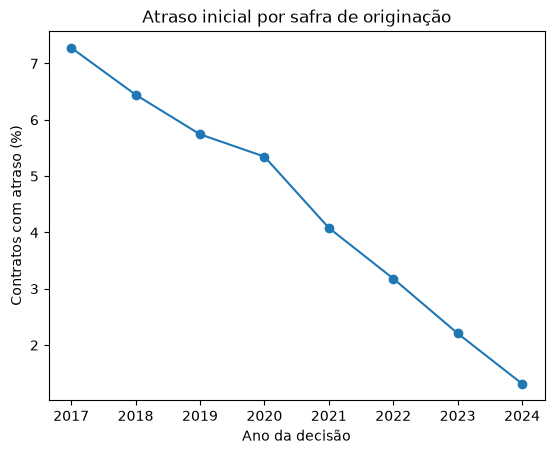

In [4]:
DIAS_ATRASO = 7
rotulos = montar_target(DIAS_ATRASO)
safra = rotulos.groupby(rotulos["data_decisao"].dt.year)["target"].agg(
    contratos="size",
    eventos="sum",
    taxa="mean")

display(safra)
safra.loc[safra.index < 2025, "taxa"].mul(100).plot(
    marker="o", 
    ylabel="Contratos com atraso (%)", 
    xlabel="Ano da decisão", 
    title="Atraso inicial por safra de originação")

plt.show()

Alvo adotado. Um contrato aprovado é positivo se alguma das três primeiras parcelas foi paga mais de 7 dias corridos após o vencimento ou ficou sem pagamento registrado até o fim dessa janela. A base permitiu classificar 101.816 dos 116.182 contratos aprovados (87,6%). Os 14.366 restantes ficaram fora por falta de parcelas com vencimento observável ou de maturidade. 

Na safra de 2024, o corte de 7 dias produziu 238 eventos, contra 78 no corte de 15 dias e 13 no de 30 dias. A primeira versão do vencimento produziria 234 eventos no corte de 7 dias. A diferença é pequena nessa safra, embora o instante em que a revisão ocorreu continue desconhecido. O proxy mede atraso inicial. Uma aplicação voltada a perda financeira exigiria outro desfecho.

A taxa observada passou de 7,28% em 2017 para 1,31% em 2024 entre os contratos rotuláveis. Mudanças de produto, originação e cobertura do rótulo são hipóteses para investigar. A safra de 2025 tem apenas um contrato observável e fica fora da comparação.

## 3. Quais sinais existiam no momento da solicitação?

O baseline usa produto, valor solicitado e valor do bem. Na submissão, `valor_credito` significa valor solicitado. No histórico, o equivalente documentado é `valor_solicitado`. O valor liberadoe o status da decisão atual ficam fora. A parcela estimada fica fora até confirmar se no histórico ela corresponde à estimativa anterior à decisão.

O segundo modelo acrescenta quantidade de decisões anteriores e recência. Datas iguais ficam de fora por falta de ordem confiável intradia. No histórico, `data_decisao` aproxima a data da solicitação. Um atraso anterior exigiria provar quando cada revisão e pagamento entrou no sistema. O cadastro é auditado para cobertura. Seu uso como feature exige valores históricos com data de vigência.

In [5]:
def montar_sinais(base, data, valor):
    sinais = base[["id_cliente", "tipo_contrato", "valor_bem", data, valor]].copy()
    sinais = sinais.rename(columns={data: "data_evento", valor: "valor_pedido"})
    assert sinais["data_evento"].notna().all() and sinais["id_cliente"].notna().all()
    sinais["ordem"] = np.arange(len(sinais))
    resultado = pd.merge_asof(
        sinais.sort_values("data_evento"),
        historico_diario.sort_values("data_anterior"),
        left_on="data_evento",
        right_on="data_anterior",
        by="id_cliente",
        allow_exact_matches=False
    ).sort_values("ordem").reset_index(drop=True)
    resultado["decisoes_anteriores"] = resultado["decisoes_anteriores"].fillna(0).astype(int)
    resultado["dias_desde_decisao"] = (resultado["data_evento"] - resultado["data_anterior"]).dt.days
    resultado["tipo_contrato"] = resultado["tipo_contrato"].astype("string").fillna("Ausente").astype(str)
    return resultado 

historico_diario = (
    contratos.assign(data_anterior=contratos["data_decisao"].dt.normalize())
    .groupby(["id_cliente", "data_anterior"], as_index=False)
    .size().sort_values("data_anterior")
)

historico_diario["decisoes_anteriores"] = historico_diario.groupby("id_cliente")["size"].cumsum()

# Cortamos por dia nos dois lados para excluir qualquer decisão no mesmo dia
amostra = contratos.loc[contratos.id_contrato.isin(rotulos.index)].copy()
amostra["data_decisao"] = amostra["data_decisao"].dt.normalize()
sub = solicitacoes.assign(data_solicitacao=solicitacoes["data_solicitacao"].dt.normalize())
treinavel = montar_sinais(amostra, "data_decisao", "valor_solicitado")
pontuar = montar_sinais(sub, "data_solicitacao", "valor_credito")
assert pontuar.id_cliente.equals(solicitacoes.id_cliente.reset_index(drop=True))

for dados in (treinavel, pontuar):
    assert (dados.data_anterior.isna() | dados.data_anterior.lt(dados.data_evento)).all()

treinavel["target"] = amostra.id_contrato.map(rotulos["target"]).to_numpy()
treinavel["data_rotulo"] = amostra.id_contrato.map(rotulos["data_rotulo"]).to_numpy()

## 4. O histórico acrescenta informação fora do tempo?

Usando 2022-2023 como janela inicial de treino e 2024 como avaliação fora do tempo, para priorizar as safras recentes e manter uma avaliação anual completa. No treino exigimos que o rótulo já pudesse ser conhecido antes do início de 2024. A validação mede a performance retrospectiva em contratos aprovados e rotuláveis. A população de todas as novas solicitações pode se comportar de outra forma.

Comparamos a prevalência constante de treino, a regressão logística com termos da proposta e a mesma regressão com histórico. A AP mede a qualidade do ranking para eventos raros, com a prevalência da validação como referência. O Brier mede a qualidade das probabilidades. Comparando por faixa de risco e por presença de histórico antes de propor uma ação. 

In [6]:
inicio_treino = pd.Timestamp("2022-01-01")
inicio_validacao = pd.Timestamp("2024-01-01")
fim_validacao = pd.Timestamp("2025-01-01")

datas = treinavel.data_evento

treino = treinavel.loc[
    datas.ge(inicio_treino) & datas.lt(inicio_validacao) & treinavel.data_rotulo.lt(inicio_validacao)
]

validacao = treinavel.loc[
    datas.ge(inicio_validacao) & datas.lt(fim_validacao)
].copy()

assert treino.target.nunique() == validacao.target.nunique() == 2
print(f"Treino: {len(treino)} contratos, {treino.target.sum():,} eventos")
print(f"Validação: {len(validacao)} contratos, {validacao.target.sum():,} eventos")

Treino: 33785 contratos, 947 eventos
Validação: 18099 contratos, 238 eventos


In [7]:
def ajustar(base, colunas):

    numericas = [col for col in colunas if col != "tipo_contrato"]

    preparar = ColumnTransformer([
        ("num", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=25), ["tipo_contrato"])
    ])

    modelo = make_pipeline(preparar, LogisticRegression(max_iter=400, C=0.1, random_state=42))
    
    return modelo.fit(base[colunas], base["target"])

proposta = ["tipo_contrato", "valor_pedido", "valor_bem"]

experimentos = {
    "proposta": proposta,
    "proposta + historico": proposta + ["decisoes_anteriores", "dias_desde_decisao"]
}

predicoes = {
    "prevalencia de treino": np.full(len(validacao), treino["target"].mean())
}

for nome, colunas in experimentos.items():
    modelo = ajustar(treino, colunas)
    predicoes[nome] = modelo.predict_proba(validacao[colunas])[:, 1]

metricas = []
for nome, pd_estimada in predicoes.items():
    metricas.append({
        "modelo": nome,
        "roc_auc": roc_auc_score(validacao["target"], pd_estimada),
        "average_precision": average_precision_score(validacao["target"], pd_estimada),
        "brier": brier_score_loss(validacao["target"], pd_estimada),
        "score_medio": pd_estimada.mean(),
        "taxa_observada": validacao.target.mean()
    })

display(pd.DataFrame(metricas).set_index("modelo"))

,roc_auc,average_precision,brier,score_medio,taxa_observada
modelo,,,,,
prevalencia de treino,0.500000,0.013150,0.013198,0.028030,0.01315
proposta,0.608550,0.020576,0.013192,0.028613,0.01315
proposta + historico,0.601373,0.018850,0.013177,0.027773,0.01315


Na validação de 2024, **1.32% dos contratos apresentaram atraso inicial**. Como o evento é raro e o uso inicial do score é priorizar propostas para revisão, a **Average Precision (AP)** foi a principal métrica de escolha. O modelo **proposta** obteve AP de **0,0206**, contra **0,0189** com a inclusão do histórico e **0,0132** no baseline de score constante. A ROC-AUC seguiu a mesma ordem, com **0,609** para proposta e **0,601** para proposta + histórico. O resultado indica capacidade modesta de ordenar o risco.

A inclusão do histórico reduziu ligeiramente o Brier, de **0,013192** para **0,013177**. Ainda assim, ambos os modelos superestimaram a taxa observada. O score médio foi de **2,86%** para proposta e **2,78%** para proposta + histórico, frente a **1,32%** de atrasos observados.

**Escolha Final: Modelo Proposta**

O modelo obteve o melhor ranking na validação e depende apenas de informações da solicitação, o que simplifica sua aplicação. Dada a diferença entre a taxa prevista e a obervada, o uso inicial recomendado é testar a priorização de propostas em modo sombra. O uso das probabilidades para definir cortes de crédito exige verificar e, se necessário, ajustar a calibração em uma safra posterior.

,volume,eventos,observado,previsto
faixa,,,,
"(0.00044000000000000007, 0.0216]",1810,13,0.007182,0.016242
"(0.0216, 0.025]",1810,16,0.008840,0.023763
"(0.025, 0.026]",1810,18,0.009945,0.025430
"(0.026, 0.0269]",1810,12,0.006630,0.026496
"(0.0269, 0.0276]",1819,22,0.012095,0.027286
"(0.0276, 0.0282]",1801,27,0.014992,0.027915
"(0.0282, 0.0289]",1810,26,0.014365,0.028592
"(0.0289, 0.0326]",1834,24,0.013086,0.030781
"(0.0326, 0.0376]",1814,29,0.015987,0.035312


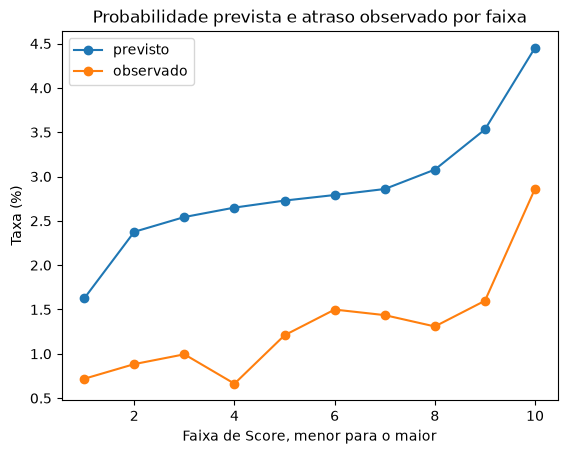

,contratos,eventos,taxa_observada,taxa_prevista
possui histórico,,,,
False,3384,49,0.014480,0.028047
True,14715,189,0.012844,0.028744


In [8]:
MODELO_ESCOLHIDO = "proposta"
validacao["score"] = predicoes[MODELO_ESCOLHIDO]
validacao["faixa"] = pd.qcut(validacao.score, q=10, duplicates="drop")
faixas = validacao.groupby("faixa", observed=True).agg(
    volume=("target", "size"),
    eventos=("target","sum"),
    observado=("target","mean"),
    previsto=("score","mean")
)

display(faixas)
faixas [["previsto","observado"]].mul(100).set_axis(range(1, len(faixas) + 1)).plot(
    marker="o",
    xlabel= "Faixa de Score, menor para o maior",
    ylabel="Taxa (%)",
    title= "Probabilidade prevista e atraso observado por faixa"
)
plt.show()

display(validacao.groupby(validacao.decisoes_anteriores.gt(0)).agg(
    contratos=("target", "size"),
    eventos=("target","sum"),
    taxa_observada=("target","mean"),
    taxa_prevista=("score","mean")
).rename_axis("possui histórico"))

## 5. Que decisão a evidência suporta?

Simulamos a capacidade da equipe de crédito, encaminhando os maiores scores de 2%, 5% e 10% da validação. Comparando quantos contratos entrariam na fila e qual parte dos eventos ela concentraria. Em produção, um limiar precisa ser fixado em uma amostra de referência e revisto se o volume ou o perfil mudarem. Empates na fronteira exigem regra operacional.

**Política Proposta:** Começar em modo sombra. Registrar score, versão do modelo, decisão vigente e desfecho quando maduro. Se o sinal se sustentar prospectivamente com volume suficiente, testar revisão humana das propostas mais arriscadas, com checagem da capacidade de pagamento e qualidade dos dados. Uma eventual mudança de prazo, limite ou aprovação exige evidência de perda e custo, validação prospectiva e governança. O backtest estima concentração de atrasos na população aprovada. Para medir perdas evitadas ou efeito sobre aprovação seria preciso observar decisões e resultados de uma política avaliada prospectivamente.

In [9]:
ordenada = validacao.sort_values("score", ascending= False, kind="stable")

cenarios = []

for capacidade in (.02, .05, .10):
    fila = ordenada.head(int(np.ceil(capacidade * len(ordenada))))
    cenarios.append({
        "capacidade": capacidade,
        "contratos revisados": len(fila),
        "eventos na fila": fila.target.mean(),
        "lift sobre a carteira": fila.target.mean() / ordenada.target.mean()
    })

display(pd.DataFrame(cenarios))

,capacidade,contratos revisados,eventos na fila,lift sobre a carteira
0,0.02,362,0.022099,1.680579
1,0.05,905,0.029834,2.268782
2,0.10,1810,0.028177,2.142739


Na simulação, revisar os 5% com maior score colocaria 905 propostas na fila e capturaria 27 dos 238 eventos (11,3%). A taxa nessa fila foi de 2,98%, cerca de 2,27 vezes a taxa observada na carteira de validação. É um cenário para medir capacidade e concentração de atraso em modo sombra. A decisão de iniciar um piloto depende de confirmação prospectiva, especialmente porque a avaliação histórica cobre aprovados rotuláveis e o score superestima a taxa de atraso

## 6. Geração da Submissão e Operação 

Para respeitar o momento da solicitação, o ajuste final usa somente contratos cujo rótulo estava maduro antes da primeira data da submissão. Se a submissão começar antes do fim da validação, o notebook exclui os rótulos posteriores do ajuste final. Nesse caso, a avaliação de 2024 tem caráter retrospectivo.

In [10]:
corte_submissao = pontuar.data_evento.min()
base_final = treinavel.loc[
    datas.ge(inicio_treino) 
    & datas.lt(min(corte_submissao, fim_validacao)) 
    & treinavel.data_rotulo.lt(corte_submissao)
]

assert base_final.target.nunique() == 2
print(f"Primeira data da submissao: {corte_submissao.date()}")
print(f"Ajuste final: {len(base_final):,} contratos, {base_final.target.sum():,} eventos")

colunas = experimentos[MODELO_ESCOLHIDO]
final = ajustar(base_final, colunas)
arquivo = solicitacoes[["id_cliente"]].copy()
arquivo["probabilidade_inadimplencia"] = final.predict_proba(pontuar[colunas])[:,1]

assert len(arquivo) == len(solicitacoes) and arquivo.id_cliente.is_unique
assert arquivo.probabilidade_inadimplencia.between(0,1).all()

arquivo.to_csv("submissao_case.csv", index=False, float_format= "%.8f")
print(f"CSV exportado com {len(arquivo):,} linhas.")

Primeira data da submissao: 2025-02-04
Ajuste final: 58,545 contratos, 1,300 eventos
CSV exportado com 40,000 linhas.


## 7. Considerações Finais

O notebook foi organizado na mesma ordem em que o problema seria tratado em uma análise de crédito. Primeiro, a checagem das bases e a construção do alvo delimitam quais contratos tem uma janela de observação suficiente para medir atraso inicial. Em seguida, as variáveis são avaliadas conforme sua disponibilidade no momento da solicitação, e a validação temporal verifica se o modelo treinado em safras anteriores consegue ordenar o risco na safra de 2024. Por fim, a simulação de uma fila de revisão traduz as métricas em uma decisão operacional.

A **regressão logística** foi escolhida como primeiro modelo por ser proporcional ao volume de eventos observados e ao objetivo do case. Com 238 eventos na validação de 2024, a prioridade era verificar se poucas informações disponíveis na solicitação já ofereciam sinal útil. A regressão regularizada permite fazer esse teste com um pipeline simples de reproduzir e facilita a análise da direção das associações entre as variáveis e o risco estimado.

**LightGBM e XGBoost** poderiam capturar relações não lineares e interações entre as variáveis. Como esses modelos não foram testados neste estudo, a escolha da regressão logística se apoia na simplicidade da solução e no desempenho observado frente ao baseline. Uma comparação futura pode usar os mesmos cortes temporais e verificar se o ganho em Average Precision e na captura de eventos por capacidade de revisão se mantém em uma safra posterior.